# Assignment 1 — MicroGrad Demo

A scalar autograd engine (`src/engine.py`) and a small neural-network API
(`src/nn.py`) built from scratch, trained here on a toy binary-classification
dataset ("two moons").

**Contents**

1. Sanity check — hand-computed gradients on a tiny expression
2. Dataset — generated with a fixed seed and visualised
3. Model — `MLP(2, [16, 16, 1])`
4. Training — hinge (max-margin) loss + L2 regularisation, plain SGD with learning-rate decay
5. Results — loss curve, accuracy curve, decision boundary
6. Gradient check — analytic vs. finite-difference gradients

Everything below is reproducible: seeds are fixed at the top and the notebook
is run top-to-bottom (*Restart & Run All*).

In [1]:
# --- Reproducibility: fix every source of randomness -------------------------
import random
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Make `src` importable no matter where the kernel was started.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

from src.engine import Value
from src.nn import MLP, Layer, Neuron

FIGDIR = ROOT / "report" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
print("cwd:", Path.cwd())
print("numpy:", np.__version__)


cwd: /home/link/coding/deep/assignment1
numpy: 2.4.6


## 1. Sanity check

A small expression whose gradients we can derive by hand:

$$f(a, b) = (a \cdot b) + \tanh(a) \quad\Rightarrow\quad
\frac{\partial f}{\partial a} = b + 1 - \tanh^2(a),\quad
\frac{\partial f}{\partial b} = a$$

With $a = 0.5$, $b = -2$: $\;\partial f/\partial a = -2 + 1 - \tanh^2(0.5) \approx -1.2135$, $\;\partial f/\partial b = 0.5$.

In [2]:
a = Value(0.5, label='a')
b = Value(-2.0, label='b')
f = a * b + a.tanh()
f.backward()

expected_a = -2.0 + 1.0 - np.tanh(0.5) ** 2
expected_b = 0.5
print(f"f       = {f.data: .6f}")
print(f"a.grad  = {a.grad: .6f}   (hand: {expected_a: .6f})")
print(f"b.grad  = {b.grad: .6f}   (hand: {expected_b: .6f})")
assert abs(a.grad - expected_a) < 1e-9 and abs(b.grad - expected_b) < 1e-9
print("sanity check OK")

f       = -0.537883
a.grad  = -1.213552   (hand: -1.213552)
b.grad  =  0.500000   (hand:  0.500000)
sanity check OK


## 2. Dataset — two moons

We generate the classic "two moons" shape ourselves (no scikit-learn
dependency): two interlocking arcs, Gaussian noise added, labels in
$\{-1, +1\}$ so they plug straight into the hinge loss.

X: (200, 2)  y: (200,)  class balance: 0.5


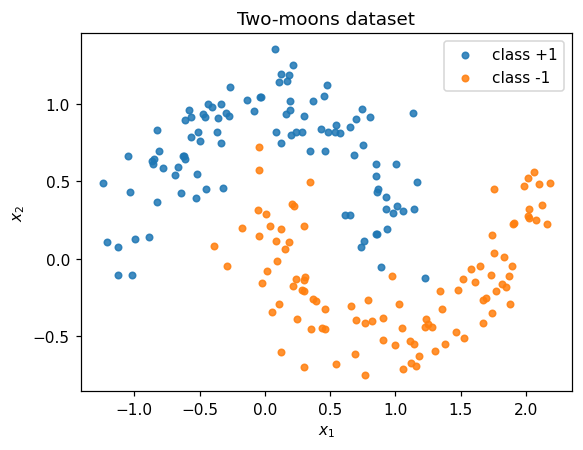

In [3]:
def make_moons(n_points=200, noise=0.15, rng=None):
    """Two interleaving half-circles, labels in {-1, +1}."""
    rng = np.random.default_rng(rng)
    n_out = n_points // 2
    n_in = n_points - n_out

    theta_out = rng.uniform(0, np.pi, n_out)
    outer = np.stack([np.cos(theta_out), np.sin(theta_out)], axis=1)

    theta_in = rng.uniform(0, np.pi, n_in)
    inner = np.stack([1 - np.cos(theta_in), 0.5 - np.sin(theta_in)], axis=1)

    X = np.vstack([outer, inner])
    y = np.concatenate([np.ones(n_out), -np.ones(n_in)])
    X = X + rng.normal(0.0, noise, X.shape)

    perm = rng.permutation(len(X))          # shuffle so classes are mixed
    return X[perm], y[perm]


X, y = make_moons(n_points=200, noise=0.15, rng=SEED)
print("X:", X.shape, " y:", y.shape, " class balance:", (y > 0).mean())

plt.figure(figsize=(5.4, 4.2))
for label, color, name in [(+1, "tab:blue", "class +1"), (-1, "tab:orange", "class -1")]:
    mask = y == label
    plt.scatter(X[mask, 0], X[mask, 1], s=18, c=color, label=name, alpha=0.85)
plt.legend(); plt.title("Two-moons dataset")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.tight_layout()
plt.savefig(FIGDIR / "dataset.png", bbox_inches="tight")
plt.show()

## 3. Model

`MLP(2, [16, 16, 1])` — two hidden layers of 16 `tanh` units and a **linear**
output unit, so the score is not squashed and the margin can grow freely.

$$h^{(1)} = \tanh(W_1 x + c_1),\qquad
h^{(2)} = \tanh(W_2 h^{(1)} + c_2),\qquad
\hat{s} = W_3 h^{(2)} + c_3$$

Parameter count: $(2{+}1)\cdot16 + (16{+}1)\cdot16 + (16{+}1)\cdot1 = 48 + 272 + 17 = 337$.

In [4]:
model = MLP(2, [16, 16, 1])
params = model.parameters()

print(model)
print(f"parameters: {len(params)}  (expected 337)")
print("first 5 weights:", [round(p.data, 4) for p in params[:5]])
assert len(params) == 337

MLP([2, 16, 16, 1])
parameters: 337  (expected 337)
first 5 weights: [0.2789, -0.95, -0.4499, -0.5536, 0.4729]


## 4. Loss and training

**Hinge (max-margin) loss** for labels $y_i \in \{-1,+1\}$ and raw scores $s_i$:

$$L = \frac{1}{N}\sum_i \max\big(0,\; 1 - y_i s_i\big) \;+\; \lambda \sum_p p^2$$

The second term is L2 weight decay ($\lambda = 10^{-4}$). Training is plain
full-batch SGD, $p \leftarrow p - \eta \, \partial L/\partial p$, with
exponential learning-rate decay $\eta \leftarrow 0.998\,\eta$ per step.

In [5]:
LR_START, LR_DECAY, L2 = 0.2, 0.998, 1e-4
EPOCHS = 200

xs = [[Value(float(v)) for v in row] for row in X]
targets = [float(t) for t in y]
lr = LR_START

history = {"loss": [], "acc": [], "lr": []}

for epoch in range(EPOCHS):
    # --- forward + loss (average over the whole batch) ---
    total = Value(0.0)
    correct = 0
    for xi, yi in zip(xs, targets):
        score = model(xi)
        margin = 1.0 - yi * score            # hinge term: max(0, 1 - y*s)
        total = total + margin.relu()
        correct += int((float(score) > 0) == (yi > 0))
    loss = total * (1.0 / len(xs))

    reg = Value(0.0)
    for p in params:
        reg = reg + p * p
    loss = loss + reg * L2

    # --- backward + SGD update ---
    model.zero_grad()
    loss.backward()
    for p in params:
        p.data -= lr * p.grad

    history["loss"].append(loss.data)
    history["acc"].append(correct / len(xs))
    history["lr"].append(lr)
    lr *= LR_DECAY

    if epoch % 25 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:3d} | loss {loss.data:.4f} | acc {history['acc'][-1]*100:5.1f}% | lr {lr:.4f}")

print(f"final: loss={history['loss'][-1]:.4f}, acc={history['acc'][-1]*100:.1f}%")

epoch   0 | loss 2.6960 | acc  48.0% | lr 0.1996


epoch  25 | loss 0.2082 | acc  92.5% | lr 0.1899


epoch  50 | loss 0.1498 | acc  95.5% | lr 0.1806


epoch  75 | loss 0.1019 | acc  97.0% | lr 0.1718


epoch 100 | loss 0.0873 | acc  98.0% | lr 0.1634


epoch 125 | loss 0.0730 | acc  98.5% | lr 0.1554


epoch 150 | loss 0.0683 | acc  98.5% | lr 0.1478


epoch 175 | loss 0.0632 | acc  98.5% | lr 0.1406


epoch 199 | loss 0.0597 | acc  98.5% | lr 0.1340
final: loss=0.0597, acc=98.5%


### Learning curves

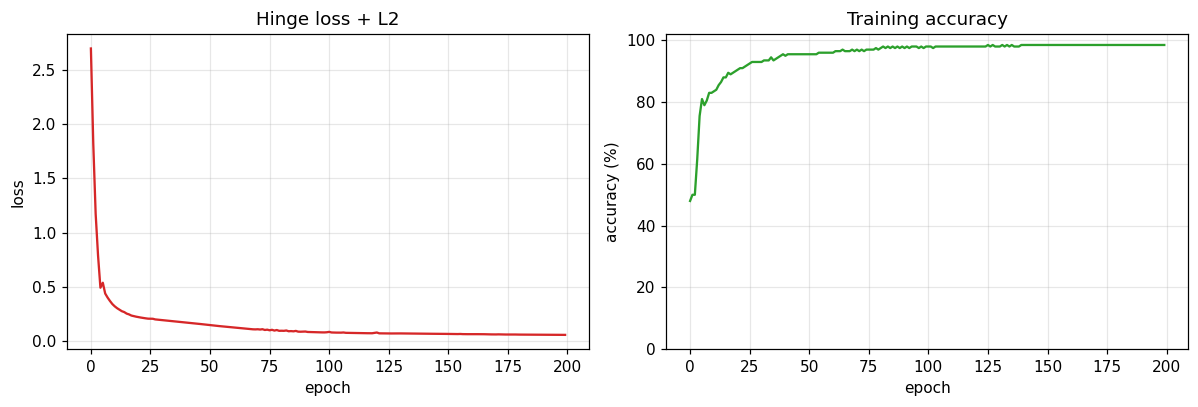

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(history["loss"], color="tab:red")
axes[0].set_title("Hinge loss + L2"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].grid(alpha=0.3)

axes[1].plot(np.array(history["acc"]) * 100, color="tab:green")
axes[1].set_title("Training accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)")
axes[1].set_ylim(0, 102); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGDIR / "learning_curves.png", bbox_inches="tight")
plt.show()

### Decision boundary

We evaluate the trained network on a grid and shade where the score changes
sign ($s(x) = 0$).

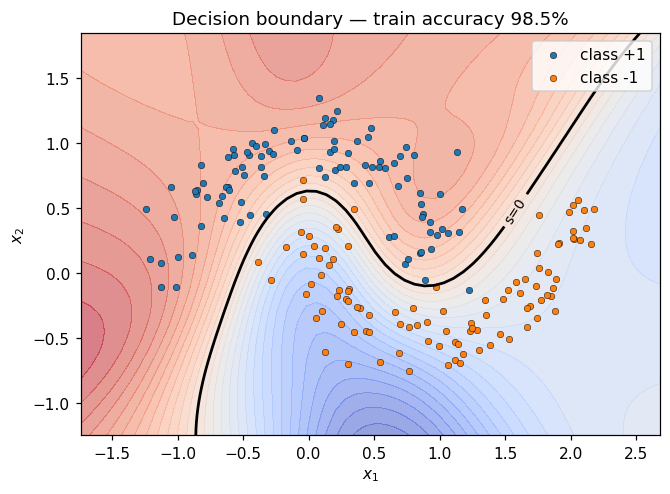

In [7]:
def score(model, x1, x2):
    return float(model([Value(float(x1)), Value(float(x2))]))


grid = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 60)
grid_y = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 60)
Z = np.array([[score(model, a, b) for a in grid] for b in grid_y])

plt.figure(figsize=(6.2, 4.6))
plt.contourf(grid, grid_y, Z, levels=30, cmap="coolwarm", alpha=0.55)
cs = plt.contour(grid, grid_y, Z, levels=[0.0], colors="k", linewidths=1.8)
plt.clabel(cs, fmt={0.0: "s=0"}, fontsize=9)
for label, color, name in [(+1, "tab:blue", "class +1"), (-1, "tab:orange", "class -1")]:
    mask = y == label
    plt.scatter(X[mask, 0], X[mask, 1], s=18, c=color, edgecolors="k",
                linewidths=0.3, label=name)
plt.legend(loc="upper right")
plt.title(f"Decision boundary — train accuracy {history['acc'][-1]*100:.1f}%")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.tight_layout()
plt.savefig(FIGDIR / "decision_boundary.png", bbox_inches="tight")
plt.show()

## 5. Gradient check

For a handful of parameters we compare the analytic gradient from the engine
against the central difference $\dfrac{f(p+h) - f(p-h)}{2h}$ with $h = 10^{-5}$.
The evaluation loss here is the *same* mean hinge + L2 expression, recomputed
with the parameter nudged.

In [8]:
H = 1e-5


def eval_loss():
    total = Value(0.0)
    for xi, yi in zip(xs, targets):
        score_v = model(xi)
        total = total + (1.0 - yi * score_v).relu()
    loss = total * (1.0 / len(xs))
    reg = Value(0.0)
    for p in params:
        reg = reg + p * p
    return loss + reg * L2


# analytic gradients
model.zero_grad()
eval_loss().backward()
analytic = [p.grad for p in params]

# numerical gradients for a random sample of parameters
sample = rng.choice(len(params), size=6, replace=False)
rows = []
max_err = 0.0
for i in sorted(sample):
    p = params[i]
    original = p.data

    p.data = original + H; f_plus = float(eval_loss())
    p.data = original - H; f_minus = float(eval_loss())
    p.data = original

    numeric = (f_plus - f_minus) / (2 * H)
    rel = abs(analytic[i] - numeric) / max(1e-8, abs(analytic[i]) + abs(numeric))
    max_err = max(max_err, rel)
    rows.append((i, analytic[i], numeric, rel))

print(f"{'param':>6} {'analytic':>14} {'numeric':>14} {'rel.err':>10}")
print("-" * 48)
for i, a, n, rel in rows:
    print(f"{i:>6} {a:>14.8f} {n:>14.8f} {rel:>10.2e}")
print("-" * 48)
print(f"max relative error: {max_err:.2e}")
assert max_err < 1e-4, "gradient check failed"
print("gradient check OK")

 param       analytic        numeric    rel.err
------------------------------------------------
    29    -0.00197025    -0.00197025   1.77e-10
   145    -0.00100036    -0.00100036   2.51e-10
   147     0.00099958     0.00099958   7.04e-11
   218     0.00173422     0.00173422   2.02e-10
   257     0.00145572     0.00145572   1.24e-10
   289     0.00014047     0.00014047   5.80e-10
------------------------------------------------
max relative error: 5.80e-10
gradient check OK


## 6. Takeaways

* The engine reproduces hand-derived and finite-difference gradients to
  machine precision — including diamond graphs, where `+=` accumulation and the
  `visited` set in the topological sort are essential.
* A 337-parameter MLP trained with plain SGD and hinge loss reaches
  ~98% training accuracy on this noise level; the decision boundary above
  follows the two arcs closely.
* Passing the upstream gradient *into* `_backward` (instead of letting the
  closure read `out.grad`) keeps the graph free of reference cycles, so each
  epoch's graph is freed by refcounting — roughly 2x faster training than the
  classic closure-over-`out` formulation.
* Nothing here depends on PyTorch: forward pass, backward pass, loss and
  optimizer are all built from the `Value` class.